# Synthetische Trainingsverträge

Begrenzter CTGAN-Pilot: 20.000 reale Trainingsverträge je Fold, drei Seeds, zwei Ratios und Bootstrap-Kontrollen. Ausschließlich reale Entwicklungs-OOF-Verträge; keine Evaluation. [Auswertung und Methode](../docs/synthetische_trainingsdaten.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if not (root / 'reports').is_dir():
    root = root.parent
r = json.loads((root / 'reports/o2/report.json').read_text(encoding='utf-8'))
print('Lauf:', r['run_id'])
print('Entscheidung:', r['decision'])
print('Explorativ:', r['exploratory'], '| Evaluation verwendet:', r['evaluation_used'])

Lauf: o2-b71e81d7f2c7a4fe
Entscheidung: discard_for_this_pilot
Explorativ: True | Evaluation verwendet: False


,method,ratio,seed,policies,poisson_deviance_per_exposure,actual_over_predicted
0,bootstrap,0.25,17,542392,0.465062,1.010560
1,bootstrap,0.25,29,542392,0.465509,1.014189
2,bootstrap,0.25,43,542392,0.465081,1.001603
3,bootstrap,1.00,17,542392,0.465899,1.011764
4,bootstrap,1.00,29,542392,0.466095,1.021299
5,bootstrap,1.00,43,542392,0.465840,0.999219
6,ctgan,0.25,17,542392,0.466417,0.997467
7,ctgan,0.25,29,542392,0.467615,0.925307
8,ctgan,0.25,43,542392,0.466095,0.922321
9,ctgan,1.00,17,542392,0.473940,0.949453


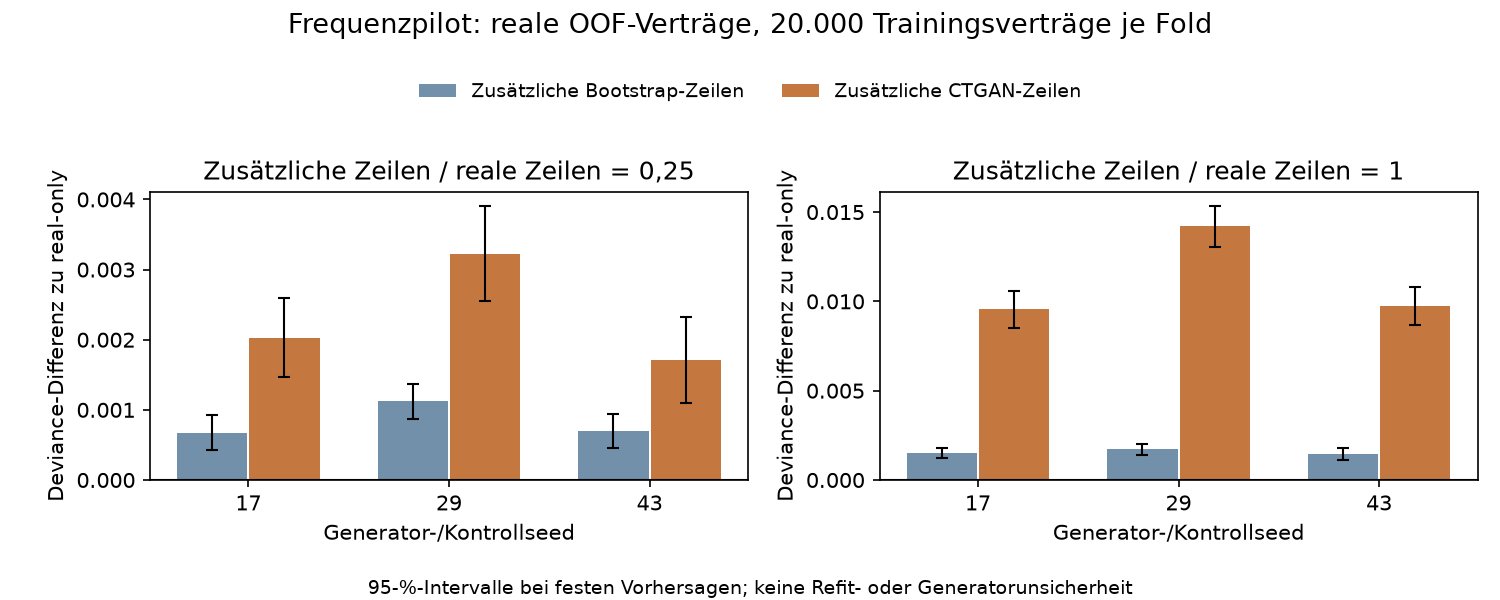

In [2]:
s = pd.DataFrame(r['scores'])
display(s[['method','ratio','seed','policies','poisson_deviance_per_exposure','actual_over_predicted']])
display(Image(filename=str(root / 'reports/o2/figures/vergleich.png')))

Die Basis nutzt dieselben festen Trainingssubsets wie die Augmentationsarme. Die Zeilenratio ist kein Exponierungsanteil. Bedingte Intervalle halten Fits fest; Seedstreuung ersetzt keine unabhängige Validierung.

In [3]:
differences = []
for x in r['scores']:
    if x['method'] == 'ctgan':
        for reference in ['vs_real','vs_bootstrap']:
            differences.append({'ratio':x['ratio'],'seed':x['seed'],'Vergleich':reference,**x[reference]})
display(pd.DataFrame(differences))
folds = pd.DataFrame(r['fold_scores'])
display(folds.pivot(index=['method','ratio','seed'], columns='fold', values='poisson_deviance_per_exposure'))
display(folds.pivot(index=['method','ratio','seed'], columns='fold', values='actual_over_predicted'))

,ratio,seed,Vergleich,conditional_95_interval,difference,standard_error
0,0.25,17,vs_real,"[0.001468532976030007, 0.002593623207978959]",0.002031,0.000287
1,0.25,17,vs_bootstrap,"[0.0007511757974757977, 0.001958306077265773]",0.001355,0.000308
2,0.25,29,vs_real,"[0.0025476427026113217, 0.003910397693369169]",0.003229,0.000348
3,0.25,29,vs_bootstrap,"[0.001372280619004083, 0.002838593333792709]",0.002105,0.000374
4,0.25,43,vs_real,"[0.0010999169425371788, 0.002318881441239348]",0.001709,0.000311
5,0.25,43,vs_bootstrap,"[0.00036479988217324327, 0.0016623826280797501]",0.001014,0.000331
6,1.00,17,vs_real,"[0.00852525877072546, 0.010583955915955831]",0.009555,0.000525
7,1.00,17,vs_bootstrap,"[0.0069695577768290355, 0.009113072833722875]",0.008041,0.000547
8,1.00,29,vs_real,"[0.013064203986181891, 0.015355001312630305]",0.014210,0.000584
9,1.00,29,vs_bootstrap,"[0.011305717706157672, 0.01369401978464614]",0.012500,0.000609


fold                         1         2         3         4         5
method    ratio seed                                                  
bootstrap 0.25  17    0.472148  0.470394  0.455773  0.466039  0.461024
                29    0.472914  0.472108  0.456308  0.465264  0.461024
                43    0.472450  0.469328  0.455987  0.465263  0.462439
          1.00  17    0.473611  0.471201  0.456185  0.466205  0.462361
                29    0.471610  0.472174  0.457571  0.467120  0.462071
                43    0.472954  0.470594  0.455952  0.466832  0.462934
ctgan     0.25  17    0.473768  0.470221  0.457639  0.467682  0.462833
                29    0.477132  0.472789  0.460715  0.464716  0.462769
                43    0.474240  0.469070  0.459482  0.465007  0.462715
          1.00  17    0.477564  0.480918  0.462463  0.480830  0.468026
                29    0.488738  0.492785  0.471738  0.471010  0.468789
                43    0.481921  0.472559  0.471455  0.477059  0.467656
real      0.00  0     0.471732  0.469964  0.455255  0.464615  0.460429

fold                         1         2         3         4         5
method    ratio seed                                                  
bootstrap 0.25  17    1.044661  1.063486  0.957784  1.042112  0.953523
                29    1.023859  1.068906  0.955770  1.057703  0.973049
                43    1.062215  1.037501  0.951037  1.039179  0.929464
          1.00  17    1.037720  1.089153  0.958733  1.026657  0.956960
                29    1.036515  1.076943  0.946868  1.083903  0.974953
                43    1.076870  1.036458  0.937070  1.017240  0.940444
ctgan     0.25  17    1.104592  0.908519  1.005731  1.032958  0.955295
                29    0.935660  0.882579  0.848530  1.060995  0.923809
                43    0.958853  1.036622  0.826797  0.888556  0.925521
          1.00  17    1.191550  0.758283  1.039132  0.923950  0.937591
                29    0.819750  0.725889  0.766579  0.972337  0.862505
                43    0.914408  0.992782  0.721510  0.753521  0.849168
real      0.00  0     1.037779  1.057294  0.942648  1.050936  0.957602

In [4]:
quality = []
for a in r['generator_audits']:
    f = a['fidelity']
    quality.append({'fold':a['fold'],'seed':a['seed'], 'verworfen':a['validity']['rejected'], 'Kandidaten':a['validity']['attempted'], 'real_null':f['real']['zero_fraction'],'synthetisch_null':f['synthetic']['zero_fraction'],'real_frequenz':f['real']['annual_rate'],'synthetisch_frequenz':f['synthetic']['annual_rate'],'exakte_Treffer':f['exact_training_row_matches']})
display(pd.DataFrame(quality))
print('Fehler:', r['failures'])

,fold,seed,verworfen,Kandidaten,real_null,synthetisch_null,real_frequenz,synthetisch_frequenz,exakte_Treffer
0,1,17,10312,40000,0.96460,0.96870,0.072104,0.059418,0
1,1,29,2916,40000,0.96460,0.92815,0.072104,0.118370,0
2,1,43,9370,40000,0.96460,0.95635,0.072104,0.118149,0
3,2,17,4158,40000,0.96435,0.91525,0.070816,0.145382,0
4,2,29,5835,40000,0.96435,0.90520,0.070816,0.143576,0
5,2,43,6667,40000,0.96435,0.95305,0.070816,0.085138,0
6,3,17,6129,40000,0.96190,0.96775,0.075990,0.070353,0
7,3,29,6155,40000,0.96190,0.93625,0.075990,0.136718,0
8,3,43,5099,40000,0.96190,0.92590,0.075990,0.165027,0
9,4,17,1990,40000,0.96470,0.95430,0.070415,0.093247,0


Fehler: []


Die Wahl wird für den vollständigen Kernvergleich nicht neu geöffnet. Der Pilot misst weder synthetische Schadenhöhe noch Datenschutz. Lokale synthetische Zeilen besitzen separate Kennungen und bleiben Trainingsartefakte.